# **Sesión 4:** Procesamiento de imagenes y extracción de características

## **Librerías**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from utils import *
from typing import List, Tuple
import glob

In [2]:
def opencv_load_images(filenames: List) -> List:
    '''
    Load images cv2.imread function (BGR)
    '''
    return [cv2.imread(filename) for filename in filenames]

source_paths = sorted(glob.glob("../data/partA-B/*"))
opencv_images = opencv_load_images(source_paths)

# **Apartado C**: Detección de puntos de interés (SIFT)

### **Tarea PREVIA:** Generamos la carpeta "../results/partC", junto con la subcarpeta "feature_extraction". Dentro de esta última, generamos las siguientes subcarpetas: "0_gaussians", "1_difference_of_gaussians", "2_match_features", "3_SIFT"

In [3]:
import os
# TODO: Define the paths of the results folders and create them

results_path = "../results/partC"
feature_extraction_path = os.path.join(results_path, "feature_extraction")
gaussians_path = os.path.join(feature_extraction_path, "0_gaussians")
dog_path = os.path.join(feature_extraction_path, "1_difference_of_gaussians")
match_features_path = os.path.join(feature_extraction_path, "2_match_features")
sift_path = os.path.join(feature_extraction_path, "3_SIFT")

os.makedirs(results_path, exist_ok=True)
os.makedirs(feature_extraction_path, exist_ok=True)
os.makedirs(gaussians_path, exist_ok=True)
os.makedirs(dog_path, exist_ok=True)
os.makedirs(match_features_path, exist_ok=True)
os.makedirs(sift_path, exist_ok=True)

### **Tarea C.1**: Generar función de filtro gaussiano

Se generará a partir de la imagen de la carpeta `data/partC` las imágenes con el filtrado gaussiano. Para ello se empleará la función `generateGaussianImages()` que tiene que desarrollar empleando la función [`cv2.GaussianBlur()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gae8bdcd9154ed5ca3cbc1766d960f45c1). Es recomendable visualizar los resultados para comprobar el funcionamiento. Para ello convierta los datos de la imagen a visualizar a `np.uint8`

In [4]:
def generateGaussianImages(image, sigmas):
    """Generate the gaussian images using the base image and the sigmas given

    Args:
        image (np.array[np.float32]): Base image to blur
        sigmas (List[np.float32]): Sigmas for blurring the image 

    Returns:
        List[np.array[np.float32]: List of blurred images
    """
    gaussian_images = []

    # TODO: Generate the list of blurred images using cv2.GaussianBlur()
    for i, sigma in enumerate(sigmas):
        image = cv2.GaussianBlur(image, (0, 0), sigmaX=sigma, sigmaY=sigma)
        gaussian_images.append(image)
    
    return gaussian_images
    

### **Tarea C.2**: Generación de espacio de escalas con imágenes gaussianas

Empleando la función anterior, complete la siguiente celda para generar las imágenes gaussianas

In [16]:
#TODO: Load the image in grayscale
image = cv2.imread('../data/partC/0.jpg', cv2.IMREAD_GRAYSCALE)
image = image.astype(np.float32)
# Number of differences of gaussians to generate (minimum 3, but with 3 no keypoint survives the refinement step)
intervals = 5
# Initial sigma
sigma = 1.6 
# We get the necessary sigmas from the given method generateGaussianSigmas()
sigmas = generateGaussianSigmas(sigma, intervals)
# Generate the gaussian images
gaussian_images = generateGaussianImages(image, sigmas)

for i, gaussian_image in enumerate(gaussian_images):
    cv2.imwrite(os.path.join(gaussians_path, 'gaussian_' + str(i) + '.jpg'), gaussian_image)


### **Tarea C.3**: Generación de diferencias de gaussianas

Utilizando la lista de imágenes gaussianas se generará una lista con las diferencias entre pares consegutivos. Para ello se empleará la función `generateDoGImages()` que tiene que desarrollar empleando la función [`cv2.subtract()`](https://docs.opencv.org/4.x/d2/de8/group__core__array.html#gaa0f00d98b4b5edeaeb7b8333b2de353b)

In [17]:
def generateDoGImages(gaussian_images):
    """Generate Difference-of-Gaussians list

    Args:
        gaussian_images (List[np.array[np.float32]): List of blurred images

    Returns:
        List[np.array[np.float32]: List of difference of gaussian images
    """
    dog_images = []

    # TODO: Generate the list of difference of gaussians using cv2.subtract()
    for i, (first_image, second_image) in enumerate(zip(gaussian_images, gaussian_images[1:])):
        dog_img = cv2.subtract(second_image, first_image)
        dog_images.append(dog_img)
    
    return dog_images

dog_images = generateDoGImages(gaussian_images)

for i, dog_image in enumerate(dog_images):
    cv2.imwrite(os.path.join(dog_path, 'dog_' + str(i) + '.jpg'), (dog_image + 128).clip(0, 255).astype(np.uint8))

### **Tarea C.4**: Evaluación de extremos

La función `isPixelAnExtremum()` debe evaluar si el pixel central del bloque compuesto por las regiones de las 3 imágenes es un máximo o mínimo entre ellos. Como prevención, tenga en cuenta que puede tomar valores positivos y negativos

In [7]:
def isPixelAnExtremum(first_subimage, second_subimage, third_subimage, threshold):
    """Return True if the center element of the 3x3x3 array composed of subimages is strictly greater than or less than all its neighbors, False otherwise

    Args:
        first_subimage (np.array): Patch from first gaussian
        second_subimage (np.array): Patch from second gaussian
        third_subimage (np.array): Patch from third gaussian
        threshold (float): Value threshold for the pixel

    Returns:
        Bool: True if maximum or minimum, False otherwise
    """
    extremum = False
    
    # TODO: Check if the center pixel value is a maximum or a minimum and if its absolute value is higher than the threshold
    center_pixel = second_subimage[1, 1]
    
    if abs(center_pixel) > threshold:

        second_neighbors = np.delete(second_subimage.flatten(), 4)

        if center_pixel > 0:
            extremum = (center_pixel > np.max(first_subimage) and center_pixel > np.max(second_neighbors) and center_pixel > np.max(third_subimage))

        else:
            extremum = (center_pixel < np.min(first_subimage) and center_pixel < np.min(second_neighbors) and center_pixel < np.min(third_subimage))

    return extremum

In [8]:
first_subimage = np.zeros((3,3),np.float32)
third_subimage = np.zeros((3,3),np.float32)
second_subimage = np.ones((3,3),np.float32)
isPixelAnExtremum(first_subimage,second_subimage, third_subimage, 0.03)

False

### **Tarea C.5**: Localización de puntos clave y orientación de los mismos

La función `findScaleSpaceExtrema()` obtendrá los puntos clave y su orientación a partir de las gaussianas y sus diferencias empleando, entre otras, la función `isPixelAnExtremum()`. Deberá completar las partes indicadas para recorrer todos los trios de imágenes consecutivos y evaluar los píxeles necesarios de estos.

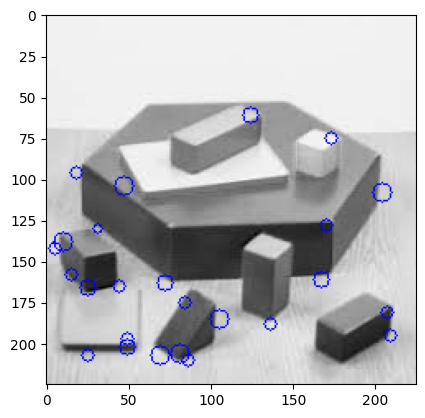

True

In [ ]:
def findScaleSpaceExtrema(gaussian_images, dog_images, num_intervals, sigma, threshold=0.03):
    """Find pixel positions of all scale-space extrema in the image pyramid """
    keypoints = []

    # TODO: Fill the loop source data
    for image_index, (first_image, second_image, third_image) in enumerate(zip(dog_images, dog_images[1:], dog_images[2:])):
        # (i, j) is the center of the 3x3 array
        # TODO: Fill the 2 range limits knowing you have to move the 3x3 window across the whole image
        for i in range(1, first_image.shape[0] - 1):
            for j in range(1, first_image.shape[1] - 1):
                # TODO: Fill the method with the required arguments
                if isPixelAnExtremum(first_image[i-1:i+2, j-1:j+2], second_image[i-1:i+2, j-1:j+2], third_image[i-1:i+2, j-1:j+2], threshold):
                    # Refine the keypoint localization
                    localization_result = localizeExtremumViaQuadraticFit(i, j, image_index + 1, num_intervals, dog_images, sigma)
                    if localization_result is not None:
                        keypoint, localized_image_index = localization_result
                        # Get the keypoint orientation
                        keypoints_with_orientations = computeKeypointsWithOrientations(keypoint, gaussian_images[localized_image_index])
                        for keypoint_with_orientation in keypoints_with_orientations:
                            keypoints.append(keypoint_with_orientation)
    return keypoints

# Keypoint Detection with Taylor Expansion and Contrast Thresholding
threshold = 0.03
keypoints = findScaleSpaceExtrema(gaussian_images, dog_images, intervals, sigma, threshold)
visualizeKp(image, keypoints)
keypoints = removeDuplicateKeypoints(keypoints)
visualizeKp(image, keypoints)

Con los puntos clave totalmente definidos y las imágenes gaussianas ya podemos obtener los descriptores con la función proporcionada de `generateDescriptors()`

In [10]:
descriptors = generateDescriptors(keypoints, gaussian_images)

### **Tarea C.6**: Pipeline de generación de puntos clave y descriptores

Complete la función con los métodos desarrollados en tareas previas para generar los puntos clave y descriptores necesarios dada una imagen, un valor de sigma y un número de diferencias de gaussianas

In [11]:
def computeKeypointsAndDescriptors(image, sigma=1.6, num_intervals=5):
    """Compute SIFT keypoints and descriptors for an input image """
    # TODO: Fill the pipeline to get the keypoint and descriptors as before
    image = image.astype('float32')
    gaussian_kernels = generateGaussianSigmas(sigma, num_intervals)
    gaussian_images = generateGaussianImages(image, gaussian_kernels)
    dog_images = generateDoGImages(gaussian_images)
    keypoints = findScaleSpaceExtrema(gaussian_images, dog_images, num_intervals, sigma)
    descriptors = generateDescriptors(keypoints, gaussian_images)
    return keypoints, descriptors

### **Tarea C.7**: Correspondencia de características entre imágenes

Cargue las imágenes con `cv2` y complete la llamada a la función previa

In [12]:
# TODO: Load the images with cv2 in grayscale
img1 = opencv_images[0].copy()
img2 = opencv_images[1].copy()

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# TODO: Fill the function calls
kp1, des1 = computeKeypointsAndDescriptors(img1)
kp2, des2 = computeKeypointsAndDescriptors(img2)

save = True
if save:
    save_path = ...
    matchFeatures_and_save(img1, kp1, des1, img2, kp2, des2, save_path)
else:
    matchFeatures(img1, kp1, des1, img2, kp2, des2)

Not enough matches are found - 0/10


#### **Ampliación**: SIFT con OpenCV

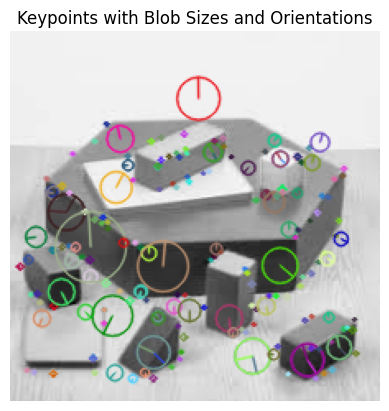

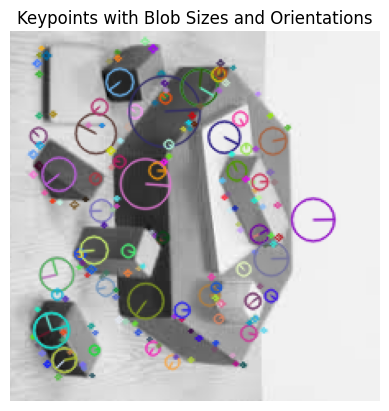

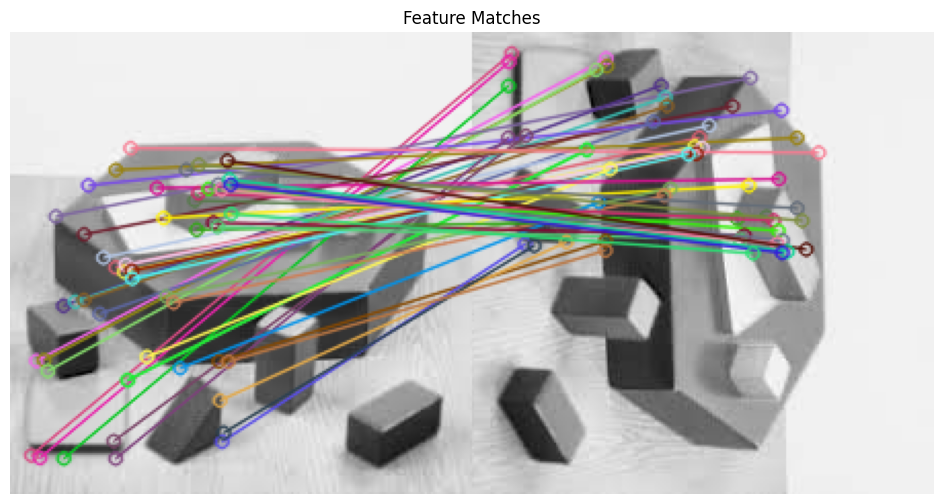

In [20]:
# Load the image
image_0 = cv2.imread('../data/partC/0.jpg', cv2.IMREAD_GRAYSCALE)
image_1 = cv2.imread('../data/partC/0_rot.jpg', cv2.IMREAD_GRAYSCALE)

# Create a SIFT detector object
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints_0, descriptors_0 = sift.detectAndCompute(image_0, None)
keypoints_1, descriptors_1 = sift.detectAndCompute(image_1, None)

# Draw keypoints on the image
image_with_keypoints_0 = cv2.drawKeypoints(image_0, keypoints_0, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints_1 = cv2.drawKeypoints(image_1, keypoints_1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.imshow(image_with_keypoints_0)
plt.title('Keypoints with Blob Sizes and Orientations')
plt.axis('off')
plt.show()
plt.imshow(image_with_keypoints_1)
plt.title('Keypoints with Blob Sizes and Orientations')
plt.axis('off')
plt.show()

# Initialize BFMatcher
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Perform KNN matching with k=2 for ratio test
matches = bf.match(descriptors_0, descriptors_1)

# sort matches by distance
matches = sorted(matches, key = lambda x:x.distance)


# Draw the good matches
matched_image = cv2.drawMatches(image_0, keypoints_0, image_1, keypoints_1, matches[:50], None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv2.imwrite(os.path.join(sift_path, 'matches_original.jpg'), matched_image)

# Display the matched features
plt.figure(figsize=(12, 6))
plt.imshow(matched_image)
plt.title("Feature Matches")
plt.axis('off')
plt.show()

### **Pregunta C.1**: Correspondencia de imágenes propias y evaluación

Con los métodos desarrollados para la extracción de características, use su *pipeline* y el SIFT de OpenCV con sus propias imágenes (por ejemplo, dos fotos de un mismo objeto desde puntos de vista distintos). Adjunte los resultados de ambos y compárelos extrayendo sus propias conclusiones.

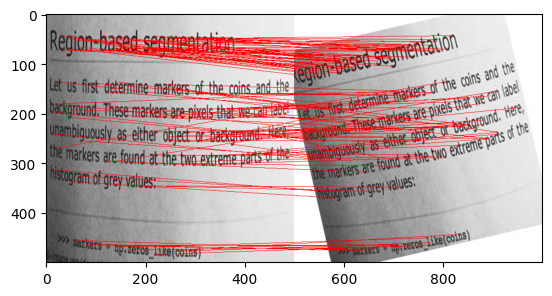

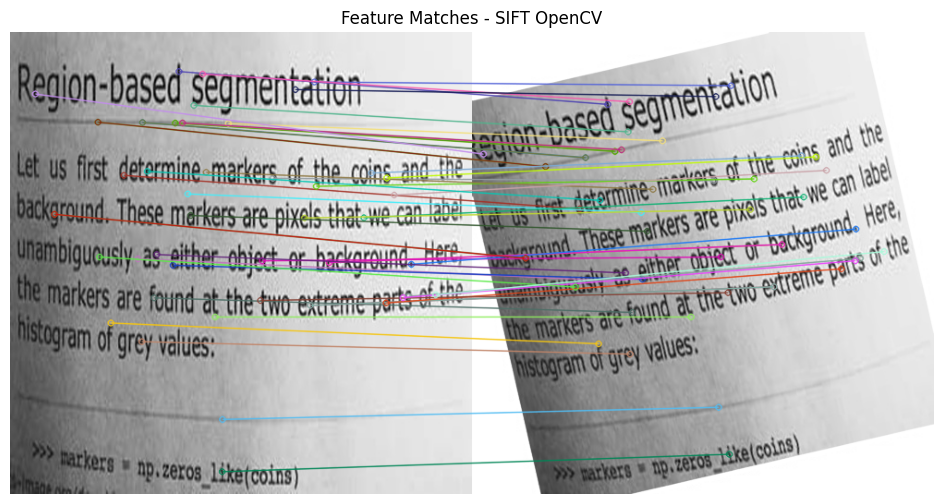

In [15]:
# TODO: Homework

image_0 = cv2.imread('../data/partC/propia_1.jpg', cv2.IMREAD_GRAYSCALE)
image_1 = cv2.imread('../data/partC/propia_2.jpg', cv2.IMREAD_GRAYSCALE)

kp1, des1 = computeKeypointsAndDescriptors(image_0)
kp2, des2 = computeKeypointsAndDescriptors(image_1)

save_path = os.path.join(match_features_path, 'homework_pipeline.jpg')
matchFeatures_and_save(image_0, kp1, des1, image_1, kp2, des2, save_path)

sift = cv2.SIFT_create()
keypoints_0, descriptors_0 = sift.detectAndCompute(image_0, None)
keypoints_1, descriptors_1 = sift.detectAndCompute(image_1, None)

bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
matches = bf.match(descriptors_0, descriptors_1)
matches = sorted(matches, key=lambda x:x.distance)

matched_image = cv2.drawMatches(image_0, keypoints_0, image_1, keypoints_1, matches[:50], None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv2.imwrite(os.path.join(sift_path, 'homework_sift.jpg'), matched_image)

plt.figure(figsize=(12, 6))
plt.imshow(matched_image)
plt.title('Feature Matches - SIFT OpenCV')
plt.axis('off')
plt.show()
